#Raw Dataset Description

Source: The dataset was custom-collected from Facebook comments, posts, and reactions from various individuals.

Number of sentences: 30 (Tagalog-English / Taglish sentences).

Word Counts: Evaluated programmatically during the preprocessing pipeline

Identifying the language of each word prior to processing is a critical step in mixed-language datasets, as it dictates the morphological rules that must be applied to extract accurate word counts and lemmas.

In [ ]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords, words
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required NLTK datasets
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('words', quiet=True)

# Load dataset

url = 'https://raw.githubusercontent.com/mohammadrayangubat/Tag-Lish-NLP-30-Sentences-/refs/heads/main/nlp_dataset.csv'

df = pd.read_csv(url)

# Pre-load English vocabulary and basic stopwords for cleaning
english_vocab = set(words.words())
english_stopwords = set(stopwords.words('english'))
tagalog_stopwords = {
    'ang', 'mga', 'si', 'ng', 'n ang', 'at', 'o', 'dahil', 'kaya', 'kasi',
    'ako', 'ikaw', 'mo', 'dito', 'ni', 'na', 'sa', 'yung', 'kang', 'ka', 'lang', 'may'
}
custom_stopwords = tagalog_stopwords.union(english_stopwords)

# Initialize standard stemmer and lemmatizer
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# --- Language Identification Logic ---
tagalog_prefixes = ['nag', 'mag', 'pag', 'pa', 'na', 'ma', 'um', 'in', 'i']
common_tech_words = {'alt-tab', 'ctrl', 'shift', 'print', 'type', 'search', 'click', 'run', 'save', 'localhost', 'port'}

def identify_language(word):
    word_lower = word.lower()

    # 1. Check English first to prevent false Taglish overlaps (e.g., 'inbound')
    if word_lower in english_vocab or word_lower in english_stopwords or word_lower in common_tech_words:
        return 'English'

    # 2. Iterate through prefixes to identify both hyphenated and unhyphenated Taglish
    for prefix in tagalog_prefixes:
        if word_lower.startswith(prefix):
            # Slice the string from the end of the prefix to the end of the word
            root = word_lower[len(prefix):]

            # Strip any lingering hyphens so 'nag-print' and 'nagprint' both yield 'print'
            root = root.lstrip('-')

            if root in english_vocab or root in common_tech_words:
                return 'Taglish'

    # 3. Default fallback
    return 'Tagalog'

# --- Item 3: Stemming Implementation (Rule-based Tagalog) ---
def tagalog_stemmer(word):
    word_lower = word.lower()
    prefixes = r'^(nag|mag|pag|pinag|ipag|ipa|pa|na|ma|um|in|i|ka)'
    suffixes = r'(in|an|han)$'

    # 1. Strip standard prefixes
    stem = re.sub(prefixes, '', word_lower)

    stem = re.sub(r'(?<=[a-zA-Z])(um|in)(?=[a-zA-Z])', '', stem)

    # 2. Handle basic CV reduplication (e.g., 'lalakad' -> 'lakad', 'kakain' -> 'kain')
    if len(stem) > 4 and stem[0:2] == stem[2:4]:
        stem = stem[2:]

    # 3. Strip suffixes
    stem = re.sub(suffixes, '', stem)

    # Clean up any leftover hyphens
    stem = stem.replace('-', '')

    return stem if len(stem) > 2 else word_lower

#Execution and Output Generation
**Implementation Details:**
This block iterates through the dataset to fulfill the remaining elements of the first three instructions. It tokenizes the text, counts the words categorized by their respective languages for Item 1, applies the appropriate stemming (Item 3), and generates the final lemmatized vocabulary representing the cleaned lexicon (Item 2). For English words, standard robust algorithms are applied, while rule-based affix stripping handles the highly agglutinative Tagalog and Taglish tokens.

In [ ]:
# Initialize data collection
language_counts = {'English': 0, 'Tagalog': 0, 'Taglish': 0}
lemmatized_vocabulary = set()

# Process each sentence
for index, row in df.iterrows():
    # Tokenize and keep alphanumeric or hyphenated words
    tokens = [word for word in word_tokenize(str(row['taglish_sent'])) if word.isalnum() or '-' in word]

    for token in tokens:
        # Ignore pure numbers or single special characters
        if not re.search('[a-zA-Z]', token): continue

        # 1. Count by Language
        lang = identify_language(token)
        language_counts[lang] += 1

        # Apply Item 3 (Stemming) and Item 2 (Lemmatization) logic
        if lang == 'English':
            stemmed_word = stemmer.stem(token.lower())
            lemmatized_word = lemmatizer.lemmatize(token.lower())

        elif lang == 'Taglish':
            root = token.lower().split('-')[-1] if '-' in token else token.lower()
            stemmed_word = stemmer.stem(root)
            lemmatized_word = lemmatizer.lemmatize(root)

        else:
            stemmed_word = tagalog_stemmer(token)
            lemmatized_word = stemmed_word # Lemma acts as stem in rule-based Tagalog logic

        # Add to Item 2 (Cleaned Lexicon) if it is not a stopword
        if token.lower() not in custom_stopwords:
            lemmatized_vocabulary.add(lemmatized_word)

# --- Item 1 Outputs ---
print(f"--- 1. Raw Dataset Statistics ---")
print(f"Source: Facebook comments, posts, and reactions")
print(f"Total Sentences: {len(df)}")
print(f"Total English Words: {language_counts['English']}")
print(f"Total Tagalog Words: {language_counts['Tagalog']}")
print(f"Total Taglish Words: {language_counts['Taglish']}\n")

# --- Item 2 Outputs ---
print(f"--- 2. Lemmatized Vocabulary (Cleaned Lexicon) ---")
print(f"Total Unique Lemmas extracted: {len(lemmatized_vocabulary)}")
print(sorted(list(lemmatized_vocabulary))) # Display alphabetically

--- 1. Raw Dataset Statistics ---
Source: Facebook comments, posts, and reactions
Total Sentences: 30
Total English Words: 226
Total Tagalog Words: 216
Total Taglish Words: 8

--- 2. Lemmatized Vocabulary (Cleaned Lexicon) ---
Total Unique Lemmas extracted: 238
['abogado', 'agad', 'alam', 'aliases', 'also', 'always', 'anong', 'areas', 'automatic', 'avoid', 'ay', 'ba', 'backtick', 'baguh', 'baha', 'balik', 'barangay', 'bata', 'baul', 'bawas', 'bawat', 'benepisyo', 'bigay', 'birth', 'boib', 'browse', 'browser', 'bsit', 'budget', 'bumukas', 'center', 'certificate', 'certificates', 'cf', 'charging', 'chat', 'claude', 'click', 'code', 'colorcoded', 'comelon', 'compact', 'context', 'copilot', 'costs', 'crowded', 'ctrl', 'custom', 'cut', 'daga', 'dami', 'dapat', 'dating', 'death', 'design', 'developer', 'development', 'di', 'diretso', 'dn', 'doors', 'drama', 'dun', 'dutae', 'election', 'element', 'ex', 'expedition', 'experience', 'filipino', 'first', 'fishing', 'focus', 'frontend', 'gamit', '

#Custom Stopwords and Part-of-Speech Tagging
**Items 5 & 6 Implementation:**
Creating a unified stopword corpus (Item 5) is essential for filtering out high-frequency function words across multiple languages before generating the final meaningful vocabulary. For Part-of-Speech (POS) tagging (Item 6), this pipeline utilizes a hybrid methodology. NLTK's pos_tag algorithm is applied to tokens identified as English, utilizing its perceptron tagger trained on standard corpora. Since Tagalog is a low-resource language for off-the-shelf NLP tools, a custom rule-based POS tagger is implemented . This tagger categorizes known Tagalog stopwords into functional parts of speech (Determiners, Pronouns, Conjunctions) and uses regular expressions to detect common verb affixes.

In [ ]:
# --- Item 5: Custom Stopword Corpus Output ---
print("--- 5. Custom Stopword Corpus ---")
print(f"Total Stopwords in Custom Corpus: {len(custom_stopwords)}")
print(sorted(list(custom_stopwords)))
print("\n")

# --- Item 6: Setup POS Tagging ---
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

def tagalog_pos(word):
    word_lower = word.lower()

    # Categorize known Tagalog stopwords
    if word_lower in tagalog_stopwords:
        if word_lower in ['ang', 'mga', 'yung', 'si']: return 'DET'
        if word_lower in ['ako', 'ikaw', 'mo', 'ka', 'kang', 'ni']: return 'PRON'
        if word_lower in ['at', 'o', 'dahil', 'kasi', 'kaya']: return 'CONJ'
        return 'PART'

    # Rule-based verb detection using affixes and reduplication (Item 6)
    prefix_check = r'^(nag|mag|pag|na|ma|um|in|i|ka)'
    if re.match(prefix_check, word_lower) or (len(word_lower) > 4 and word_lower[0:2] == word_lower[2:4]):
        return 'VERB'

    # Fallback for unrecognized Tagalog words
    return 'NOUN'

--- 5. Custom Stopword Corpus ---
Total Stopwords in Custom Corpus: 218
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'ako', 'all', 'am', 'an', 'and', 'ang', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'dahil', 'did', 'didn', "didn't", 'dito', 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", "he's", 'her', 'here', 'hers', 'herself', 'him', 'himself', 'his', 'how', 'i', "i'd", "i'll", "i'm", "i've", 'if', 'ikaw', 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', 'just', 'ka', 'kang', 'kasi', 'kaya', 'lang', 'll', 'm', 'ma', 'may', 'me', 'mga', 'mightn', "mightn't", 'mo', 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'na', 'nang', 'needn', "

#Tokenized Table and Meaningful Vocabulary
**Items 4 & 7 Implementation:**
This phase iterates through the raw dataset to construct the final comprehensive output. For each token, the pipeline identifies the language and applies the corresponding stemmer, lemmatizer, and POS tagger. The processed data is appended to a list of dictionaries, which is subsequently converted into a Pandas DataFrame to fulfill the tokenized output table requirement (Item 7). Concurrently, tokens that are not present in the custom stopword corpus are extracted by their lemma to build the final custom vocabulary of unique, meaningful words (Item 4).

In [ ]:
token_data = []
meaningful_vocabulary = set()

# Process each sentence to build the final table
for index, row in df.iterrows():
    tokens = [word for word in word_tokenize(str(row['taglish_sent'])) if word.isalnum() or '-' in word]

    # Pre-calculate English POS in bulk to retain sentence context for NLTK
    english_tokens = [t for t in tokens if identify_language(t) == 'English']
    english_pos_dict = dict(nltk.pos_tag(english_tokens))

    for token in tokens:
        if not re.search('[a-zA-Z]', token): continue # Skip pure numbers/punctuation

        lang = identify_language(token)

        # Apply specific rules based on detected language
        if lang == 'English':
            stem = stemmer.stem(token.lower())
            lemma = lemmatizer.lemmatize(token.lower())
            pos = english_pos_dict.get(token, 'NN')
        elif lang == 'Taglish':
            root = token.lower().split('-')[-1] if '-' in token else token.lower()
            stem = stemmer.stem(root)
            lemma = lemmatizer.lemmatize(root)
            pos = 'VERB' # Taglish compound words are predominantly verbs
        else:
            stem = tagalog_stemmer(token)
            lemma = stem
            pos = tagalog_pos(token)

        # Add to custom vocabulary if not a stopword (Item 4)
        if token.lower() not in custom_stopwords:
            meaningful_vocabulary.add(lemma)

        token_data.append({
            'Token': token,
            'Language': lang,
            'Stem': stem,
            'Lemma': lemma,
            'POS Tag': pos
        })

# --- Item 7: Tokenized Output Table ---
token_df = pd.DataFrame(token_data)
print("--- 7. Tokenized Output Table ---")
display(token_df.head(30)) # Display first 30 tokens

# --- Item 4: Custom Vocabulary ---
print("\n--- 4. Custom Meaningful Vocabulary (Unique Words) ---")
print(f"Total Unique Meaningful Words (Lemmas): {len(meaningful_vocabulary)}")
print(sorted(list(meaningful_vocabulary)))

--- 7. Tokenized Output Table ---


,Token,Language,Stem,Lemma,POS Tag
0,Developer,English,develop,developer,NNP
1,ka,English,ka,ka,NN
2,ba,English,ba,ba,NN
3,o,English,o,o,JJ
4,BSIT,Tagalog,bsit,bsit,NOUN
5,student,English,student,student,NN
6,na,English,na,na,FW
7,may,English,may,may,MD
8,laptop,Tagalog,laptop,laptop,NOUN
9,at,English,at,at,IN



--- 4. Custom Meaningful Vocabulary (Unique Words) ---
Total Unique Meaningful Words (Lemmas): 238
['abogado', 'agad', 'alam', 'aliases', 'also', 'always', 'anong', 'areas', 'automatic', 'avoid', 'ay', 'ba', 'backtick', 'baguh', 'baha', 'balik', 'barangay', 'bata', 'baul', 'bawas', 'bawat', 'benepisyo', 'bigay', 'birth', 'boib', 'browse', 'browser', 'bsit', 'budget', 'bumukas', 'center', 'certificate', 'certificates', 'cf', 'charging', 'chat', 'claude', 'click', 'code', 'colorcoded', 'comelon', 'compact', 'context', 'copilot', 'costs', 'crowded', 'ctrl', 'custom', 'cut', 'daga', 'dami', 'dapat', 'dating', 'death', 'design', 'developer', 'development', 'di', 'diretso', 'dn', 'doors', 'drama', 'dun', 'dutae', 'election', 'element', 'ex', 'expedition', 'experience', 'filipino', 'first', 'fishing', 'focus', 'frontend', 'gamit', 'gantipala', 'gaw', 'gurong', 'habang', 'hahahaha', 'hahahahahaha', 'hassle', 'health', 'hearing', 'hehe', 'hide', 'hindi', 'hit', 'hours', 'huling', 'impeachment'

#Pipeline Diagram
**Item 8 Implementation:**
The data flow of this pipeline relies on a branching architecture. Because code-switched text cannot be processed uniformly, the language identifier acts as a routing mechanism. English tokens are routed to statistical algorithms, while Tagalog and Taglish tokens are routed to deterministic, rule-based functions before converging into the final structured DataFrame.

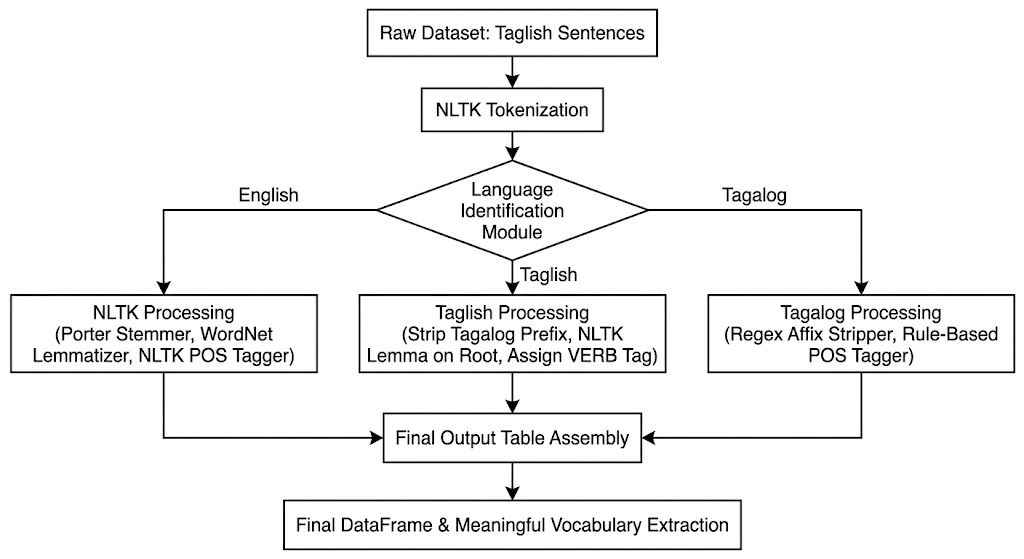